# B → Kνν: first kinematic baseline

**Goal:** understand the inclusive q² approximation before adding a detector model or GPR.

This notebook generates B → K + Q, followed by Q → νν, where Q is the invisible pair. It calculates both the exact q² and Belle II's published inclusive estimator from the same events.

**Scope:** signal kinematics only. There are no tag-B decay products, detector effects, backgrounds, trigger or selection cuts, and no trained regression. The accompanying B's four-momentum is defined for bookkeeping only.

The generated q² spectrum is **uniform**, deliberately chosen to explore the entire kinematic range. It is neither an SM prediction nor a phase-space-weighted decay model. This notebook cannot predict Belle II efficiency, resolution or GPR improvement.

Open in Jupyter and run the cells in order. Dependencies: `numpy`, `matplotlib`. All energies and momenta are in GeV; c = 1. 

In [1]:
import numpy as np
import matplotlib.pyplot as plt

N_EVENTS = 100_000
SEED = 1776
SQRT_S = 10.58
M_B = 5.27941
M_K = 0.493677
rng = np.random.default_rng(SEED)

E_B = SQRT_S / 2
P_B = np.sqrt(E_B**2 - M_B**2)
Q2_MAX = (M_B - M_K)**2
assert E_B >= M_B, "The beam energy must allow a B pair."
print(f"Events: {N_EVENTS:,}; seed: {SEED}")
print(f"B energy in collision CM: {E_B:.5f} GeV")
print(f"B momentum magnitude in collision CM: {P_B:.5f} GeV")
print(f"q² range: 0 to {Q2_MAX:.4f} GeV²")

Events: 100,000; seed: 1776
B energy in collision CM: 5.29000 GeV
B momentum magnitude in collision CM: 0.33456 GeV
q² range: 0 to 22.9032 GeV²


## 1. Generate the signal decay

In the B rest frame:
\[
E_K^{(B)}=\frac{m_B^2+m_K^2-q^2}{2m_B},\qquad
|\vec p_K^{(B)}|=\sqrt{(E_K^{(B)})^2-m_K^2}.
\]

The kaon direction is isotropic in this frame. Generate the two massless neutrinos in their pair rest frame, then boost them into the B frame. Their individual directions are sampled isotropically for this kinematic check; no matrix element for the internal neutrino angular distribution is applied.

Finally boost all three particles into the collision centre-of-mass frame. We choose the signal B to point along +z, with the other B along −z. Without beam-dependent cuts this is a coordinate choice, **not a model of the production angle relative to the beam**. A detector study will require a separate beam axis and production-angle distribution.

Four-vectors below use the order **(E, px, py, pz)**.

In [2]:
def unit_vectors(n, random):
    cos_theta = random.uniform(-1, 1, n)
    phi = random.uniform(0, 2*np.pi, n)
    sin_theta = np.sqrt(1 - cos_theta**2)
    return np.column_stack((sin_theta*np.cos(phi), sin_theta*np.sin(phi), cos_theta))

def mass_squared(p4):
    return p4[..., 0]**2 - np.sum(p4[..., 1:]**2, axis=-1)

def boost(p4, beta):
    """Active Lorentz boost by velocity beta; beta may be one vector or one per event."""
    beta = np.broadcast_to(np.asarray(beta), p4[..., 1:].shape)
    b2 = np.sum(beta**2, axis=-1)
    assert np.all(b2 < 1)
    gamma = 1 / np.sqrt(1 - b2)
    bp = np.sum(beta*p4[..., 1:], axis=-1)
    coefficient = np.divide(gamma-1, b2, out=np.zeros_like(gamma), where=b2 > 0)
    energy = gamma * (p4[..., 0] + bp)
    momentum = p4[..., 1:] + (coefficient*bp + gamma*p4[..., 0])[..., None]*beta
    return np.column_stack((energy, momentum))

# Sample away from exactly zero pair mass to avoid an undefined pair rest frame.
q2_generated = rng.uniform(1e-6, Q2_MAX, N_EVENTS)
e_k_b = (M_B**2 + M_K**2 - q2_generated) / (2*M_B)
p_k_b = np.sqrt(np.maximum(e_k_b**2 - M_K**2, 0))
k_b = np.column_stack((e_k_b, p_k_b[:, None]*unit_vectors(N_EVENTS, rng)))
pair_b = np.column_stack((M_B-e_k_b, -k_b[:, 1:]))

e_nu_pair = np.sqrt(q2_generated)/2
nu_direction = unit_vectors(N_EVENTS, rng)
nu_pair = np.column_stack((e_nu_pair, e_nu_pair[:, None]*nu_direction))
antinu_pair = np.column_stack((e_nu_pair, -e_nu_pair[:, None]*nu_direction))
beta_pair = pair_b[:, 1:] / pair_b[:, :1]
nu_b = boost(nu_pair, beta_pair)
antinu_b = boost(antinu_pair, beta_pair)

beta_b = np.array([0., 0., P_B/E_B])
k_cm = boost(k_b, beta_b)
nu_cm = boost(nu_b, beta_b)
antinu_cm = boost(antinu_b, beta_b)
b_cm = np.broadcast_to([E_B, 0., 0., P_B], k_cm.shape)
tag_cm = np.broadcast_to([E_B, 0., 0., -P_B], k_cm.shape)
print("Generated kaon and both neutrinos in the collision CM frame.")

Generated kaon and both neutrinos in the collision CM frame.


## 2. Check conservation, then calculate q²

The truth value is computed independently in two ways:
\[
q^2_{\rm true}=(p_\nu+p_{\bar\nu})^2=(p_B-p_K)^2.
\]

The published inclusive estimator is
\[
q^2_{\rm inclusive}=\frac{s}{4}+m_K^2-\sqrt{s}E_K^*.
\]

The exact expression in the collision CM frame is
\[
q^2_{\rm true}=m_B^2+m_K^2-2E_BE_K^*+2\vec p_B\cdot\vec p_K^*.
\]

Thus, even with a perfectly measured kaon, the published approximation has the residual
\[
q^2_{\rm inclusive}-q^2_{\rm true}=|\vec p_B|^2-2\vec p_B\cdot\vec p_K^*.
\]

The |pB|² term is a small offset from using s/4 instead of mB². The event-dependent term contains the unknown B–kaon angular relation. No fit or learning is involved here.

In [3]:
q2_true = mass_squared(nu_cm + antinu_cm)
q2_from_b = mass_squared(b_cm - k_cm)
q2_inclusive = SQRT_S**2/4 + M_K**2 - SQRT_S*k_cm[:, 0]
q2_exact_direction = (M_B**2 + M_K**2 - 2*E_B*k_cm[:, 0]
                      + 2*np.sum(b_cm[:, 1:]*k_cm[:, 1:], axis=1))
residual = q2_inclusive - q2_true

np.testing.assert_allclose(k_cm + nu_cm + antinu_cm, b_cm, atol=1e-8, rtol=0)
np.testing.assert_allclose(b_cm + tag_cm, np.broadcast_to([SQRT_S, 0, 0, 0], b_cm.shape), atol=1e-12)
np.testing.assert_allclose(mass_squared(k_cm), M_K**2, atol=1e-10)
np.testing.assert_allclose(mass_squared(nu_cm), 0, atol=1e-8)
np.testing.assert_allclose(mass_squared(antinu_cm), 0, atol=1e-8)
np.testing.assert_allclose(q2_true, q2_generated, atol=1e-8, rtol=0)
np.testing.assert_allclose(q2_true, q2_from_b, atol=1e-8, rtol=0)
np.testing.assert_allclose(q2_true, q2_exact_direction, atol=1e-8, rtol=0)
np.testing.assert_allclose(residual, P_B**2 - 2*P_B*k_cm[:, 3], atol=1e-8, rtol=0)

lo, hi = np.quantile(residual, [0.16, 0.84])
print("Four-momentum conservation and mass checks: PASSED")
print(f"Inclusive mean residual (bias): {residual.mean():+.4f} GeV²")
print(f"Inclusive residual standard deviation: {residual.std():.4f} GeV²")
print(f"Inclusive residual RMSE: {np.sqrt(np.mean(residual**2)):.4f} GeV²")
print(f"Inclusive central-68% half-width: {(hi-lo)/2:.4f} GeV²")
print(f"Exact-direction maximum absolute residual: {np.max(np.abs(q2_exact_direction-q2_true)):.2e} GeV²")
print("These are truth-level toy metrics for a uniform q² spectrum, not Belle II resolutions.")

Four-momentum conservation and mass checks: PASSED
Inclusive mean residual (bias): +0.0488 GeV²
Inclusive residual standard deviation: 0.6305 GeV²
Inclusive residual RMSE: 0.6324 GeV²
Inclusive central-68% half-width: 0.6268 GeV²
Exact-direction maximum absolute residual: 2.49e-14 GeV²
These are truth-level toy metrics for a uniform q² spectrum, not Belle II resolutions.


## 3. Inspect the residuals

The correlation plot shows how much the stationary-B approximation moves events away from their true q². The binned residual plot separates bias from spread; a single overall width can hide dependence on true q².

The exact-direction result is a numerical closure check, not an achievable detector resolution. It is essentially exact here because the toy has no measurement errors.

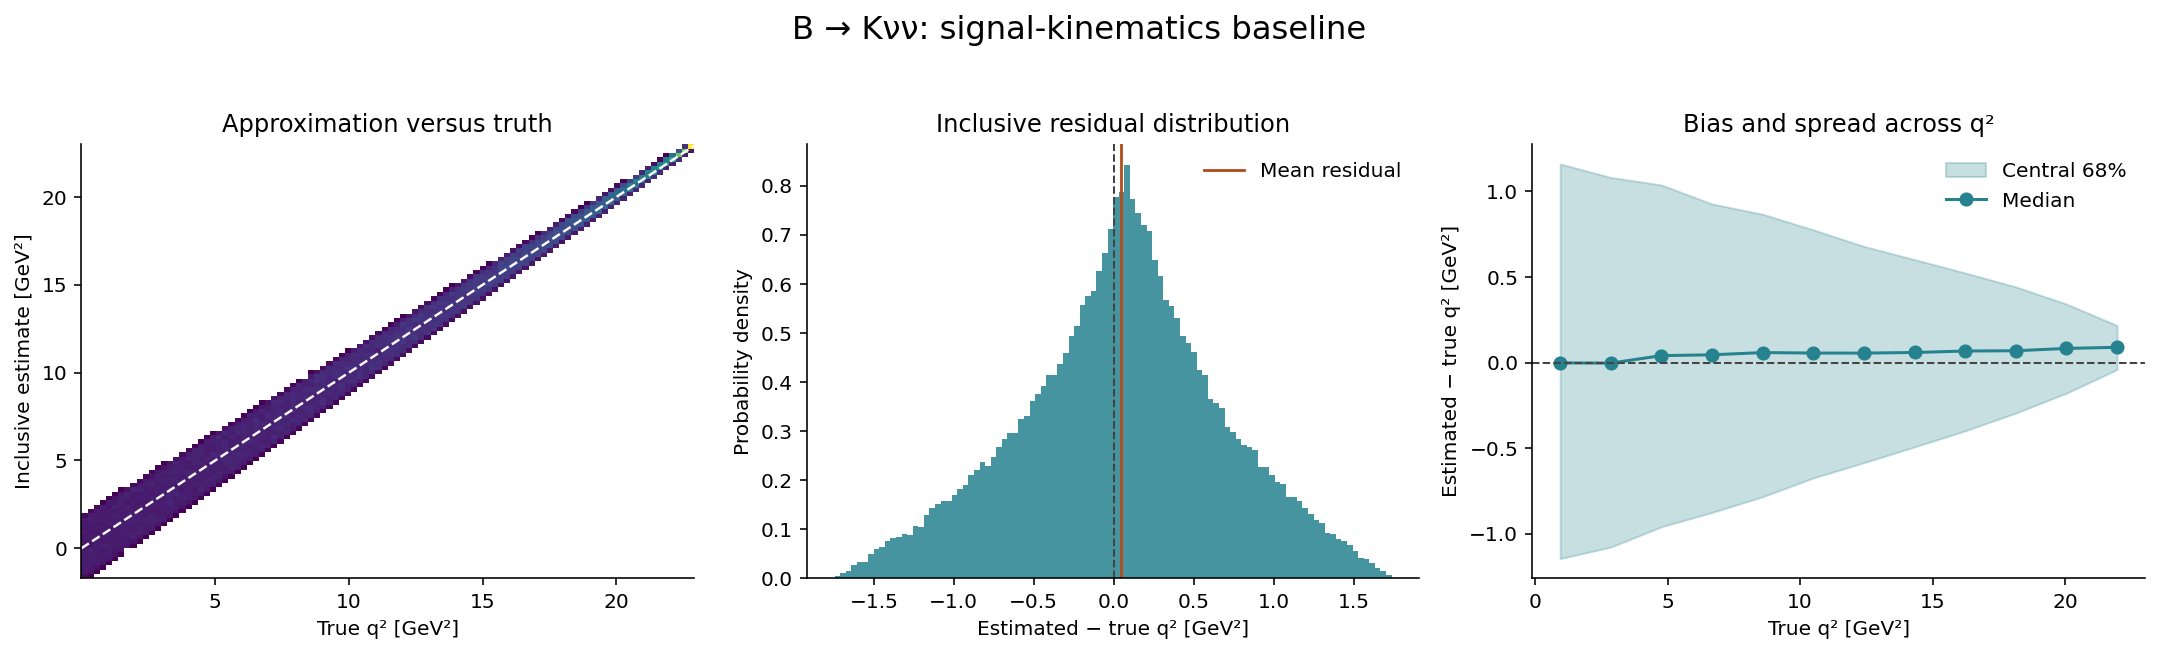

In [4]:
plt.rcParams.update({'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False})
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
fig.suptitle('B → Kνν: signal-kinematics baseline', fontsize=16, y=1.04)

h = axes[0].hist2d(q2_true, q2_inclusive, bins=100, cmap='viridis', cmin=1)
axes[0].plot([0, Q2_MAX], [0, Q2_MAX], color='white', linestyle='--', linewidth=1.2)
axes[0].set(xlabel='True q² [GeV²]', ylabel='Inclusive estimate [GeV²]', title='Approximation versus truth')

axes[1].hist(residual, bins=100, color='#26828e', alpha=.85, density=True)
axes[1].axvline(0, color='#444444', linestyle='--', linewidth=1)
axes[1].axvline(residual.mean(), color='#b34c1d', linewidth=1.4, label='Mean residual')
axes[1].set(xlabel='Estimated − true q² [GeV²]', ylabel='Probability density', title='Inclusive residual distribution')
axes[1].legend(frameon=False)

edges = np.linspace(0, Q2_MAX, 13)
centres = (edges[1:] + edges[:-1])/2
q16, q50, q84 = [], [], []
for low, high in zip(edges[:-1], edges[1:]):
    r = residual[(q2_true >= low) & (q2_true < high)]
    quantiles = np.quantile(r, [.16, .5, .84])
    q16.append(quantiles[0]); q50.append(quantiles[1]); q84.append(quantiles[2])
axes[2].fill_between(centres, q16, q84, color='#26828e', alpha=.25, label='Central 68%')
axes[2].plot(centres, q50, color='#26828e', marker='o', label='Median')
axes[2].axhline(0, color='#444444', linestyle='--', linewidth=1)
axes[2].set(xlabel='True q² [GeV²]', ylabel='Estimated − true q² [GeV²]', title='Bias and spread across q²')
axes[2].legend(frameon=False)
fig.tight_layout()
plt.show()

## What to do first

1. Run this notebook and inspect the conservation checks and three plots.
2. Change `SEED` and rerun: the conclusions should be stable within Monte Carlo fluctuations.
3. Set `SQRT_S = 2*M_B`: the B momentum becomes zero and the inclusive estimator must agree with truth. This is a mathematical limit, not a simulation of the physical production rate.

## Next milestone: construct usable GPR inputs

Before training, we need the visible particles of the accompanying B. That requires an explicitly specified tag decay model, followed by a simplified detector response. Candidate features would be calculated from those visible particles, while true signal-B information remains available only as training labels and validation targets. The fixed signal-B axis used in this notebook must also be replaced with a sampled production direction relative to a fixed beam axis: otherwise kaon vector components would implicitly reveal the true B direction.

The next toy should document its tag decay modes, their weights, acceptance, missing neutral particles, measurement errors and backgrounds. A narrow set of fully visible hadronic tag decays would be an intentionally favourable starting case; it would not represent the full inclusive sample. Varying these assumptions is part of the feasibility study.

For subsequent GPR comparisons, keep the selected events fixed, evaluate on independent events, report bias and tails alongside widths, and vary the generated q² spectrum. A relative improvement in this toy will remain conditional on its assumptions.

## Sources and conventions

- Belle II, *Evidence for B⁺ → K⁺νν decays*, [arXiv:2311.14647, Section IV, Eq. (2)](https://arxiv.org/html/2311.14647v3): inclusive q² estimator and event reconstruction. This toy implements only the estimator, not the analysis selection.
- [PDG 2025 B± listing](https://pdg.lbl.gov/2025/listings/rpp2025-list-B-plus-minus.pdf): mB = 5.27941 GeV. A fixed charged-kaon mass of 0.493677 GeV is used.
- The Lorentz transformations and residual identity are derived from four-momentum conservation. No Belle II event samples were used.
